In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

In [2]:
df = pd.read_csv('../data/processed/donnees_economiques_maroc.csv', index_col=0)
df.head()

,pib,inflation_pct,chomage_pct
2000,4.301746e+10,1.894635,13.58
2001,4.383148e+10,0.619802,12.46
2002,4.707719e+10,2.795620,11.59
2003,5.802936e+10,1.167734,11.92
2004,6.611415e+10,1.493444,10.83


In [3]:
df.describe()

,pib,inflation_pct,chomage_pct
count,2.500000e+01,25.000000,25.0000
mean,1.017417e+11,1.854982,10.0266
std,3.271647e+10,1.595539,1.2702
min,4.301746e+10,0.303386,8.8960
25%,7.588382e+10,0.971863,9.1910
50%,1.100806e+11,1.401959,9.4600
75%,1.213536e+11,1.894635,10.8300
max,1.606110e+11,6.657042,13.5800


In [4]:
print("Année d'inflation la plus élevée :", df['inflation_pct'].idxmax(), 
      f"({df['inflation_pct'].max():.2f}%)")
print("Année de chômage le plus élevé :", df['chomage_pct'].idxmax(), 
      f"({df['chomage_pct'].max():.2f}%)")
print("Année de PIB le plus élevé :", df['pib'].idxmax())

Année d'inflation la plus élevée : 2022 (6.66%)
Année de chômage le plus élevé : 2000 (13.58%)
Année de PIB le plus élevé : 2024


In [5]:
correlation = df.corr()
print(correlation)

                    pib  inflation_pct  chomage_pct
pib            1.000000       0.148988    -0.741006
inflation_pct  0.148988       1.000000    -0.152315
chomage_pct   -0.741006      -0.152315     1.000000


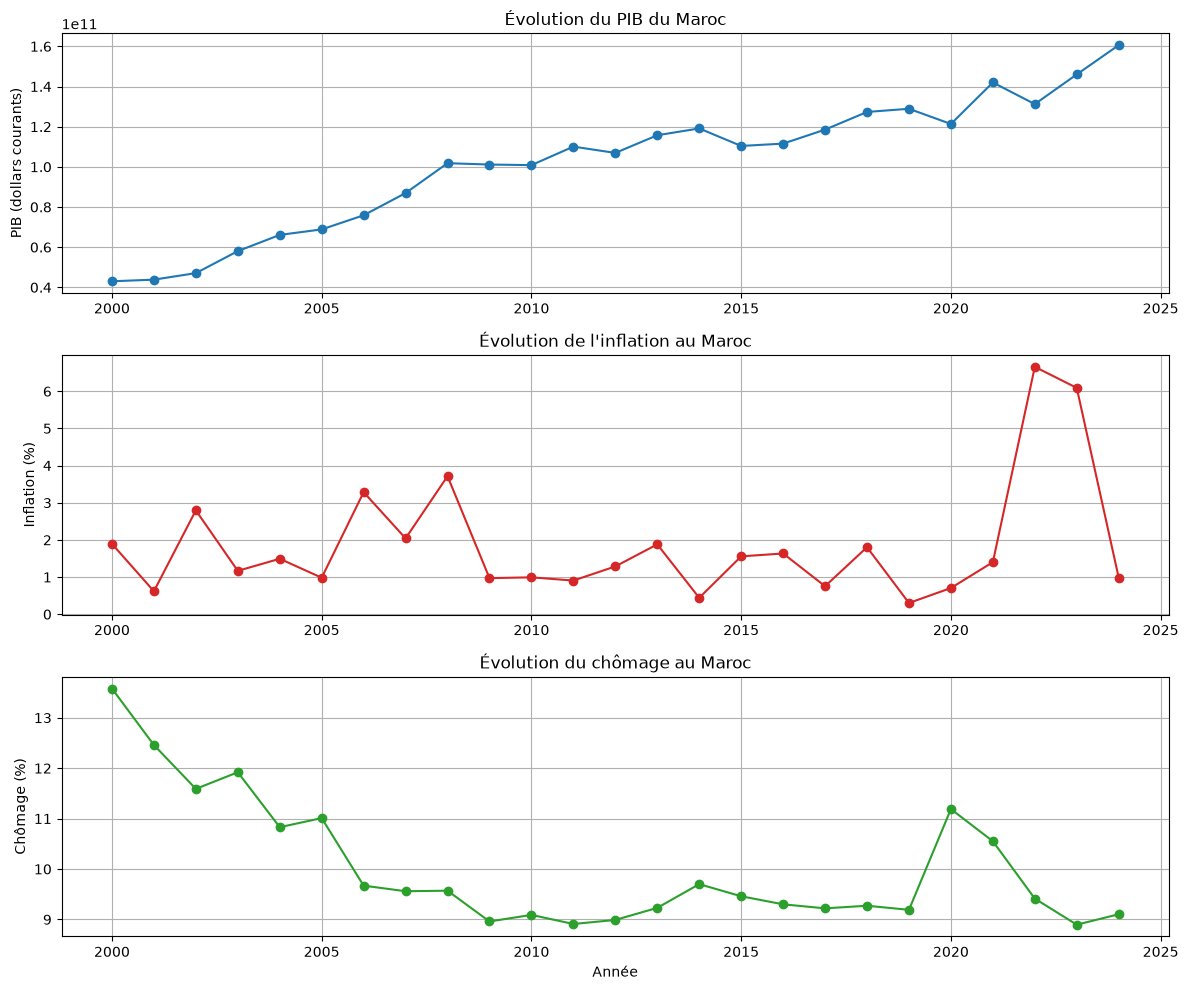

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(df.index, df['pib'], color='#1f77b4', marker='o')
axes[0].set_title("Évolution du PIB du Maroc")
axes[0].set_ylabel("PIB (dollars courants)")
axes[0].grid(True)

axes[1].plot(df.index, df['inflation_pct'], color='#d62728', marker='o')
axes[1].set_title("Évolution de l'inflation au Maroc")
axes[1].set_ylabel("Inflation (%)")
axes[1].grid(True)

axes[2].plot(df.index, df['chomage_pct'], color='#2ca02c', marker='o')
axes[2].set_title("Évolution du chômage au Maroc")
axes[2].set_ylabel("Chômage (%)")
axes[2].set_xlabel("Année")
axes[2].grid(True)

plt.tight_layout()
plt.savefig('../images/evolution_indicateurs.png', dpi=150)
plt.show()

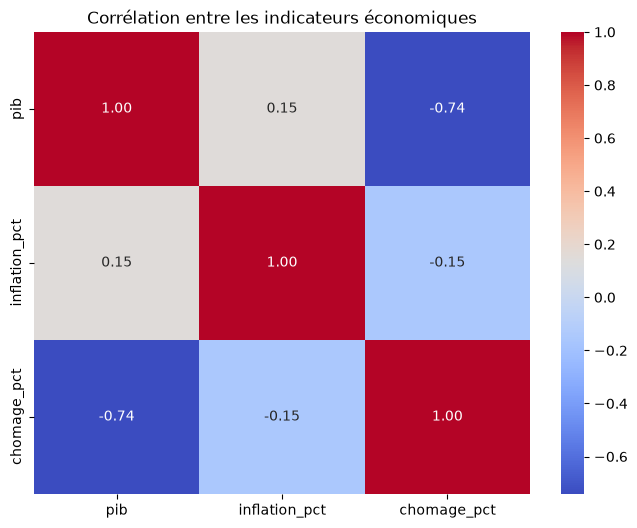

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Corrélation entre les indicateurs économiques")
plt.savefig('../images/correlation.png', dpi=150)
plt.show()

In [8]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df.index, y=df['inflation_pct'],
    mode='lines+markers', name='Inflation (%)'
))
fig.update_layout(
    title="Évolution de l'inflation au Maroc (interactif)",
    xaxis_title="Année", yaxis_title="Inflation (%)"
)
fig.write_html('../images/inflation_interactive.html')
fig.show()

## Interprétation économique des corrélations

Le PIB et le chômage affichent une corrélation forte et négative (-0.74) : sur la période 2000-2024, la croissance économique marocaine s'est globalement accompagnée d'une baisse du taux de chômage, ce qui est cohérent avec la loi d'Okun.

En revanche, le lien entre PIB et inflation reste très faible (0.15). La croissance marocaine ne semble donc pas être le principal moteur de l'inflation sur cette période. Le pic d'inflation de 2022 (6.66%) correspond à un choc externe lié à la hausse mondiale des prix de l'énergie et de l'alimentation, dans le contexte post-Covid et de la guerre en Ukraine.

La corrélation entre inflation et chômage est faible et légèrement négative (-0.15). Elle ne confirme pas clairement la courbe de Phillips sur cette période. Cette relation doit être interprétée avec prudence compte tenu du nombre limité d'années observées et du caractère atypique du choc de 2022.